# Graded outcomes: does the score track the match ratio?

At round 1's settings almost every run either recovers the whole matching or fails: only 0–6% of runs end between 0.35 and 0.85 accuracy (`fresh_pair_scores.ipynb`). Each run is close to a coin flip, so a plot of score against accuracy shows two bands. This notebook looks for settings where single runs end part-way, then asks whether the weighted score tracks the match ratio there.

**Graphs.** Round 1's ER pairs for GOAT and FAQ (600 vertices, mean degree 16) with a lower edge correlation ρ; round 1 uses ρ = 0.50. A rough check with scipy's FAQ found graded runs at ρ = 0.3: with 150 random seeds, six runs ended between 0.44 and 0.68 accuracy. At ρ = 0.4 and 0.5, runs were still all or nothing.

**Outcome.** With 100 or more seeds, the choice of seeds also changes which vertices the usual non-seed accuracy is measured on: seeding hard-to-match vertices removes them from the count. So each pair sets aside 120 fixed test vertices (20%) that are never seeds. The main outcome is the share of them matched correctly, so every seed set is judged on the same vertices. The usual non-seed accuracy is recorded too (section 7).

| Step | What it runs | Time with 3 jobs (rough) |
|---|---|---|
| 1. Pilot | FAQ and GOAT at ρ = 0.25, 0.30 and 0.35. FAQ budgets 60–260 and GOAT 20–200, 7 each. 24 random sets per budget on one pair per ρ, one run each | about 30 min |
| 2. Collection | In the chosen setting: 3 fresh pairs × 1,000 random sets, one run each. The first 50 sets of each pair run twice more with other solver seeds | about 2 h |
| 3–7. Analysis | Reads saved results only | seconds |
| 8. Rules at low ρ | Round 1's rules and best of N against random sets at ρ = 0.25, 0.30 and 0.35: 5 new pairs per ρ, 5 budgets each | about 40 min |

The frozen score uses the pooled ER weights, fitted for success at ρ = 0.5. They are never refitted, except in section 5, which fits new weights on the match ratio for comparison.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import importlib

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir())
if ROOT.name == 'selection_rule_comparison':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from selection_rule_comparison import graded_outcomes as G
G = importlib.reload(G)   # picks up edits to graded_outcomes.py without restarting the kernel

pd.set_option('display.max_rows', 300)
pd.set_option('display.width', 220)

RUN_PILOT = True
RUN_COLLECTION = True     # False: stop after the pilot and look at it first
CHOICE = None             # None: the pilot's recommendation. Or e.g. {'faq': (0.30, 150), 'goat': (0.30, 70)}
JOBS = 3
print('Results:', G.OUTPUT_DIR)

Results: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/graded_outcomes


## 1. Pilot: where do single runs end part-way?

Each dot is one run from a random seed set, and the black line is the median. The grey band is accuracy 0.2–0.8. A setting is graded when most of its dots sit inside the band and spread out, instead of stacking at the top and bottom.

`recommend()` picks, for each algorithm, the setting where at least 75% of runs end part-way and the mean is closest to 0.5, and the figure marks it in orange. If no setting qualifies for an algorithm, its collection is skipped. To choose yourself, set `CHOICE` in the cell above.

The table's Spearman uses only 24 sets per setting, so it is a rough first look.

The pilot is complete. Results are in /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/graded_outcomes/pilot


runs  failed runs  mean    sd   q10  median   q90  share part-way  non-seed accuracy  Spearman with score  seconds per run
algorithm rho  budget                                                                                                                            
SGM (FAQ) 0.25 60        24            0  0.04  0.02  0.02    0.04  0.06            0.00               0.05                -0.29              2.0
               90        24            0  0.08  0.03  0.04    0.08  0.12            0.00               0.09                 0.14              1.6
               120       24            0  0.13  0.03  0.09    0.13  0.18            0.04               0.16                 0.35              1.3
               150       24            0  0.21  0.04  0.16    0.21  0.25            0.67               0.24                 0.05              1.2
               180       24            0  0.31  0.06  0.24    0.30  0.38            1.00               0.35                 0.20              0.8
               220       24            0  0.45  0.06  0.36    0.46  0.51            1.00               0.48                 0.28              0.6
               260       24            0  0.58  0.05  0.54    0.57  0.63            1.00               0.60                 0.30              0.4
          0.30 60        24            0  0.07  0.02  0.04    0.07  0.09            0.00               0.07                 0.49              2.2
               90        24            0  0.17  0.05  0.11    0.17  0.23            0.21               0.17                 0.28              1.5
               120       24            0  0.29  0.06  0.22    0.29  0.37            0.96               0.31                 0.08              1.3
               150       24            0  0.54  0.07  0.47    0.52  0.61            1.00               0.55                 0.39              1.1
               180       24            0  0.72  0.08  0.64    0.72  0.81            0.88               0.73                -0.16              0.7
               220       24            0  0.83  0.04  0.77    0.84  0.87            0.21               0.82                -0.08              0.5
               260       24            0  0.89  0.03  0.85    0.89  0.92            0.00               0.88                -0.15              0.3
          0.35 60        24            0  0.18  0.05  0.11    0.18  0.25            0.29               0.19                 0.25              1.9
               90        24            0  0.95  0.01  0.94    0.95  0.96            0.00               0.96                 0.12              1.3
               120       24            0  0.95  0.01  0.94    0.96  0.96            0.00               0.96                -0.13              0.7
               150       24            0  0.96  0.01  0.94    0.96  0.98            0.00               0.97                -0.32              0.6
               180       24            0  0.96  0.01  0.95    0.96  0.97            0.00               0.97                 0.01              0.4
               220       24            0  0.97  0.01  0.95    0.97  0.98            0.00               0.97                -0.46              0.3
               260       24            0  0.97  0.01  0.96    0.97  0.98            0.00               0.97                -0.13              0.1
GOAT      0.25 20        24            0  0.01  0.01  0.00    0.01  0.02            0.00               0.02                 0.23              4.3
               35        24            0  0.03  0.01  0.02    0.02  0.04            0.00               0.03                -0.06              4.0
               50        24            0  0.05  0.02  0.02    0.04  0.08            0.00               0.05                -0.43              3.3
               70        24            0  0.07  0.02  0.04    0.07  0.09            0.00               0.08                 0.24              3.4
               100       24            0  0.13  0.04  0.09    0.12  0.18         

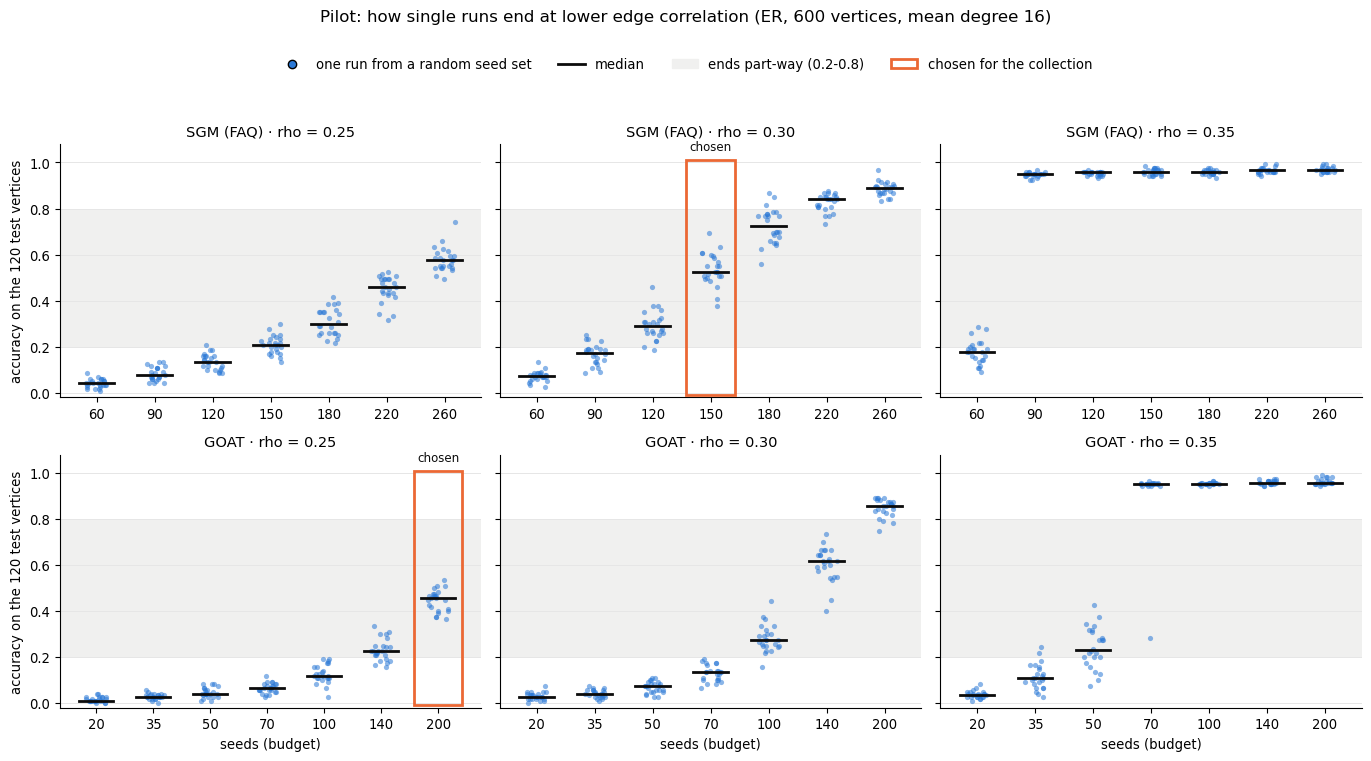

Recommended: SGM (FAQ): rho = 0.30, k = 150; GOAT: rho = 0.25, k = 200


In [2]:
if RUN_PILOT:
    G.run_pilot(jobs=JOBS)
pilot = G.read_pilot()
pilot_summary = G.pilot_table(pilot)
recommended = G.recommend(pilot_summary)
display(G.show_pilot(pilot_summary))
G.plot_pilot(pilot, CHOICE or recommended)
plt.show()
print('Recommended:', G.describe_choice(recommended))

## 2. Collection

3 fresh pairs × 1,000 random seed sets in the chosen setting, one run each, with all 11 graph-A features of every set. The first 50 sets of each pair are run twice more with other solver seeds (section 6). Pairs come from a new seed stream that skips every pair used so far, and FAQ and GOAT share pairs when they use the same ρ.

The cell prints one line per finished pair. The interrupt button stops the workers; rerunning resumes. To run in a terminal instead, from the repository root: `python -m selection_rule_comparison.graded_outcomes --collect` (add `--choice faq=0.30:150 goat=0.30:70` to choose), and `--status` to see progress.

In [3]:
choice = CHOICE or recommended
print('Collecting:', G.describe_choice(choice))
if RUN_COLLECTION:
    G.run_collection(choice, jobs=JOBS)
display(G.collection_status(choice))

Collecting: SGM (FAQ): rho = 0.30, k = 150; GOAT: rho = 0.25, k = 200
The collection is complete. Results are in /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/graded_outcomes/collection


sets done  repeat runs done
algorithm rho  budget pair                             
SGM (FAQ) 0.30 150    0          1000               100
                      1          1000               100
                      2          1000               100
GOAT      0.25 200    0          1000               100
                      1          1000               100
                      2          1000               100

## 3. How spread out are the outcomes?

Per pair: the mean and spread of the test accuracy, and the share of runs ending part-way (0.2–0.8). A wide histogram means single runs differ in how much they recover, which is what the group wanted to see.

rho  budget  sets  failed runs  test accuracy: mean     sd    q10  median    q90  share part-way  non-seed accuracy: mean
algorithm pair                                                                                                                            
SGM (FAQ) 0     0.30     150  1000            0                0.549  0.089  0.433   0.550  0.667           0.999                    0.544
          1     0.30     150  1000            0                0.687  0.098  0.550   0.692  0.808           0.891                    0.664
          2     0.30     150  1000            0                0.668  0.097  0.542   0.667  0.800           0.925                    0.667
GOAT      0     0.25     200  1000            0                0.436  0.054  0.367   0.433  0.508           1.000                    0.433
          1     0.25     200  1000            0                0.418  0.053  0.350   0.417  0.492           1.000                    0.424
          2     0.25     200  1000            0                0.411  0.054  0.342   0.408  0.483           1.000                    0.434

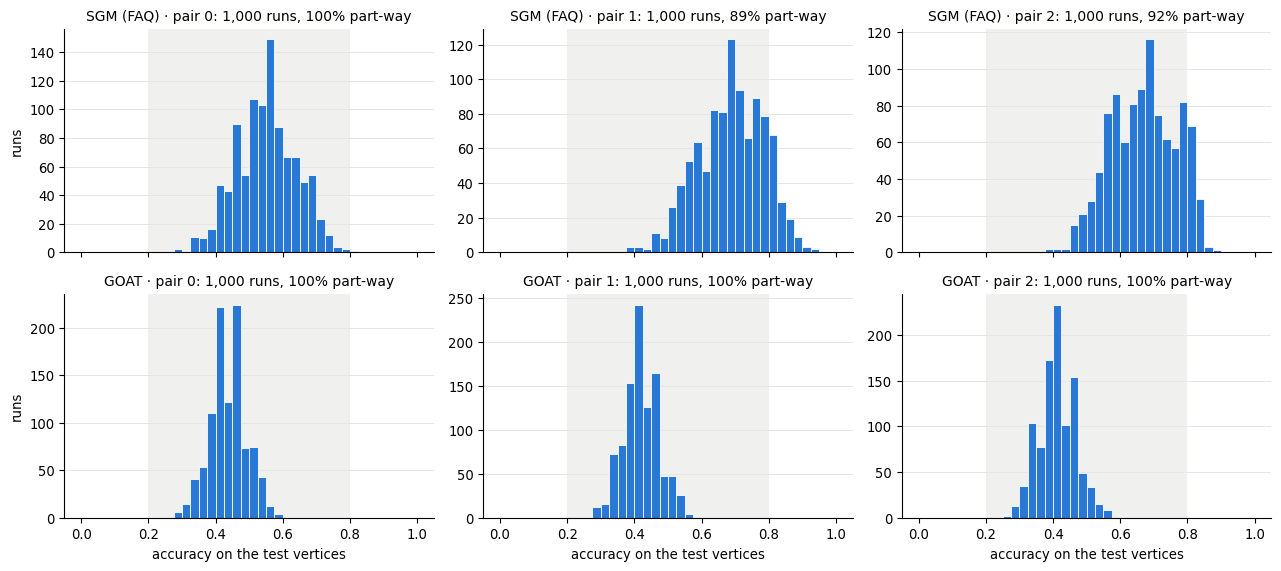

In [4]:
data = G.read_collection(choice)
display(G.outcome_table(data))
G.plot_outcomes(data)
plt.show()

## 4. Score versus match ratio

One figure per algorithm, with one column per pair:
- **Row 1:** the frozen score, fitted for success at ρ = 0.5.
- **Row 2:** degree alone.
- **Row 3:** weights refitted on this outcome with all 11 features, using the other pairs only, so each pair is scored by weights that never saw it.

Orange shows the mean outcome in each tenth of the x-axis, with 95% intervals.

In the table, Spearman is computed within each pair. The `mean` columns compare the top and bottom tenth of sets by each ranking with all sets. For reference, at round 1's ER setting (ρ = 0.5) the frozen score's Spearman with final accuracy averaged 0.29 for FAQ and 0.23 for GOAT (`fresh_pair_scores.ipynb`).

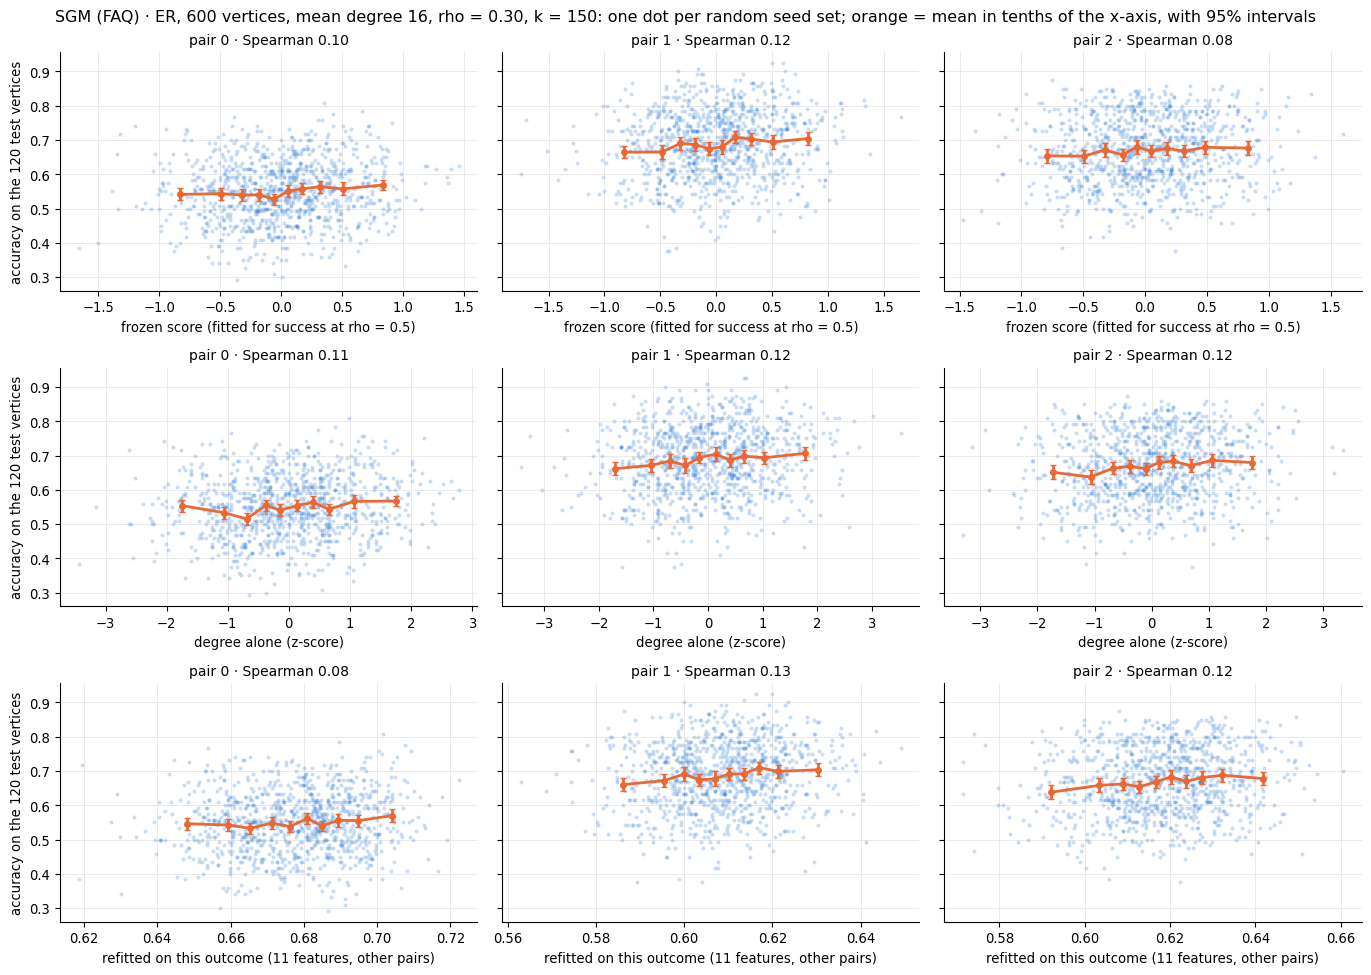

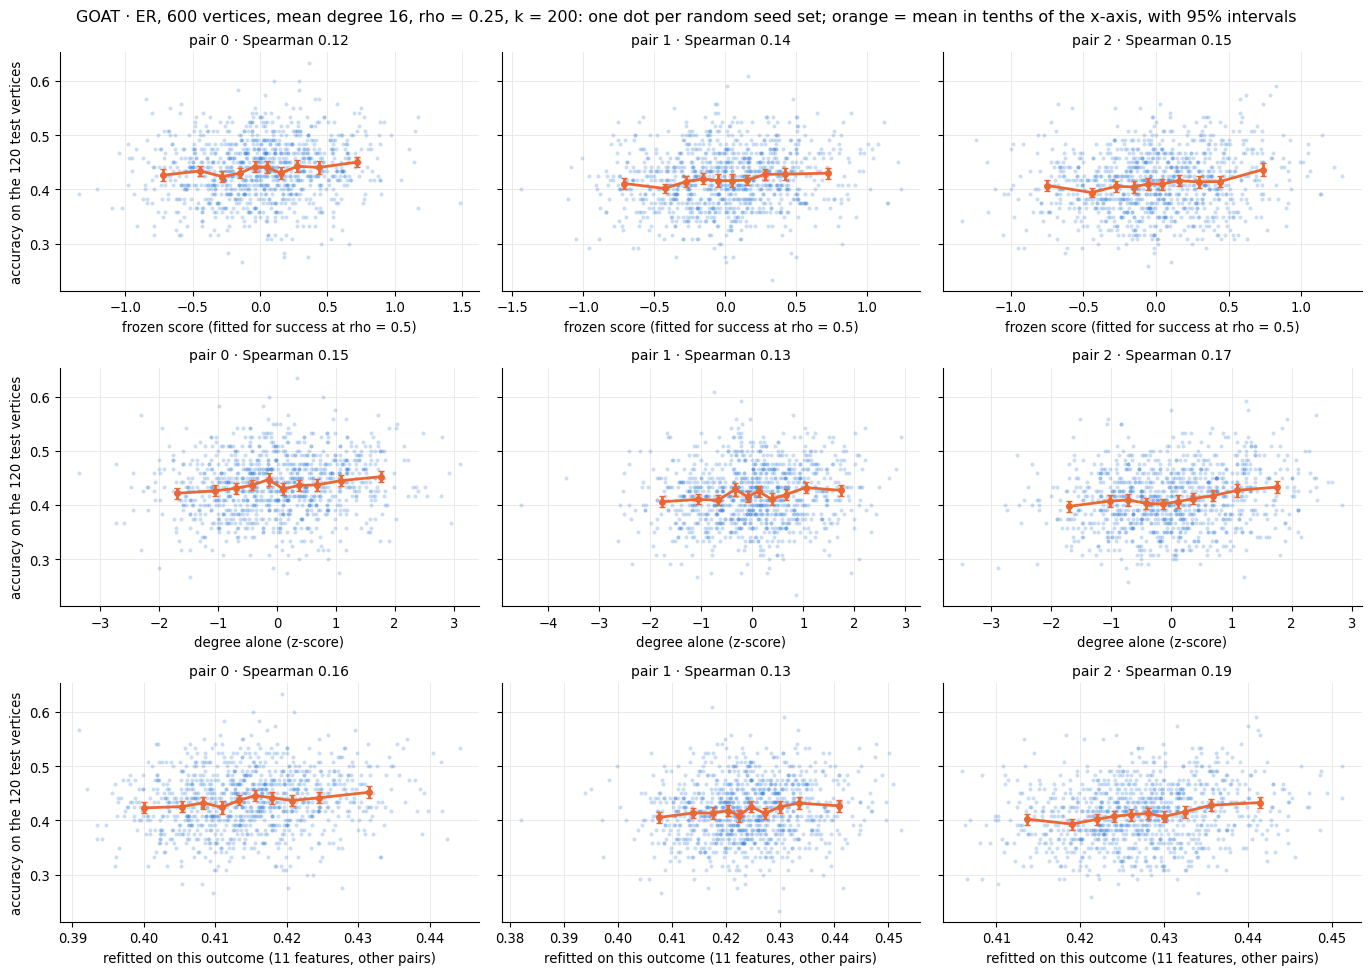

sets  Spearman: frozen score  Spearman: degree  Spearman: harmonic  Spearman: pair mass  Spearman: uniqueness  Spearman: coverage  Spearman: refit, 4 features  Spearman: refit, 11 features  \
algorithm pair                                                                                                                                                                                                              
SGM (FAQ) pair 0           1000.0                    0.10              0.11                0.04                 0.09                  0.07                0.06                         0.11                          0.08   
          pair 1           1000.0                    0.12              0.12                0.05                 0.10                  0.07                0.06                         0.10                          0.13   
          pair 2           1000.0                    0.08              0.12                0.02                 0.10                  0.00                0.04                         0.12                          0.12   
          mean over pairs  1000.0                    0.10              0.12                0.04                 0.10                  0.05                0.06                         0.11                          0.11   
GOAT      pair 0           1000.0                    0.12              0.15                0.08                 0.14                   NaN               -0.04                         0.15                          0.16   
          pair 1           1000.0                    0.14              0.13                0.12                 0.12                   NaN                0.04                         0.13                          0.13   
          pair 2           1000.0                    0.15              0.17                0.10                 0.16                   NaN               -0.02                         0.17                          0.19   
          mean over pairs  1000.0                    0.14              0.15                0.10                 0.14                   NaN               -0.01                         0.15                          0.16   

                           mean: all sets  mean: bottom 10% by frozen score  mean: top 10% by frozen score  mean: top 10% by degree  mean: top 10% by refit (11)  
algorithm pair                                                                                                                                                    
SGM (FAQ) pair 0                     0.55                              0.54                           0.57                     0.57                         0.57  
          pair 1                     0.69                              0.66                           0.70                     0.71                         0.70  
          pair 2                     0.67                              0.65                           0.68                     0.68                         0.68  
          mean over pairs            0.63                              0.62                           0.65                     0.65                         0.65  
GOAT      pair 0                     0.44                              0.43                           0.45                     0.45                         0.45  
          pair 1                     0.42                              0.41                           0.43                     0.43                         0.43  
          pair 2                     0.41                              0.41                           0.44                     0.43                         0.43  
          mean over pairs            0.42                              0.41                           0.44                     0.44                         0.44

In [5]:
for algorithm in G.algorithms_in(data):
    G.plot_scores(data, algorithm)
    plt.show()
display(G.show_ranking(G.ranking_table(data)))

## 5. Do the best weights change when the outcome is graded?

The frozen weights are in log-odds of success per SD. The refitted ones are in test accuracy per SD, with the other features held fixed. So compare signs and relative sizes, not values.

If the refit puts weight on coverage or on the distance to the nearest seed, spreading seeds out matters more when runs end part-way than when they are all or nothing.

In [6]:
display(G.weights_table(data))

frozen weight (success, rho 0.5)  refit, 4 features  refit, 11 features
algorithm feature                                                                                          
SGM (FAQ) degree                                               0.126              0.018               0.019
          harmonic                                             0.118             -0.004              -0.008
          coverage                                               NaN                NaN               0.004
          witness overlap                                        NaN                NaN               0.014
          pair mass                                            0.182             -0.005              -0.038
          distance to nearest seed                               NaN                NaN              -0.004
          seeds within 3 hops                                    NaN                NaN               0.005
          uniqueness (cap 3)                                     NaN                NaN               0.000
          Jaccard overlap                                        NaN                NaN               0.021
          uniqueness (cap 2)                                   0.203             -0.000              -0.001
          uniqueness (cap 4)                                     NaN                NaN               0.000
GOAT      degree                                               0.063              0.006               0.041
          harmonic                                             0.286              0.002               0.001
          coverage                                               NaN                NaN              -0.003
          witness overlap                                        NaN                NaN              -0.027
          pair mass                                            0.137              0.001              -0.013
          distance to nearest seed                               NaN                NaN               0.003
          seeds within 3 hops                                    NaN                NaN               0.001
          uniqueness (cap 3)                                  -0.014              0.000               0.000
          Jaccard overlap                                        NaN                NaN               0.007
          uniqueness (cap 2)                                     NaN                NaN              -0.001
          uniqueness (cap 4)                                     NaN                NaN               0.000

## 6. How much of the spread is solver luck?

The first 50 sets of each pair were run three times with different solver seeds; A, B and the seeds stay the same.
- **Share of variance from solver seed:** near 0 means a set's outcome barely changes between runs, so differences between sets come from the sets themselves (together with this pair's B).
- **Run-to-run Spearman:** how well one run of a set predicts another run of the same set. It is a ceiling for how well any score can rank single runs on this pair.

In [7]:
display(G.repeat_table(data, G.read_repeats(choice)))

sets run 3 times  SD across all sets  SD across runs of the same set  share of variance from solver seed  run-to-run Spearman
algorithm pair                                                                                                                               
SGM (FAQ) 0                   50               0.089                           0.044                               0.241                0.739
          1                   50               0.098                           0.061                               0.385                0.704
          2                   50               0.097                           0.063                               0.420                0.515
GOAT      0                   50               0.054                           0.000                               0.000                1.000
          1                   50               0.053                           0.000                               0.000                1.000
          2                   50               0.054                           0.000                               0.000                1.000

## 7. The usual non-seed accuracy

The same table as section 4, with the usual outcome: the share of all non-seeds matched correctly. If it differs much from section 4, the choice of seeds changes which vertices are counted, and section 4's fixed test vertices are the fairer measure.

In [8]:
display(G.show_ranking(G.ranking_table(data, outcome='accuracy')))

sets  Spearman: frozen score  Spearman: degree  Spearman: harmonic  Spearman: pair mass  Spearman: uniqueness  Spearman: coverage  Spearman: refit, 4 features  Spearman: refit, 11 features  \
algorithm pair                                                                                                                                                                                                              
SGM (FAQ) pair 0           1000.0                    0.10              0.10                0.03                 0.09                  0.06                0.05                         0.10                          0.07   
          pair 1           1000.0                    0.10              0.11                0.01                 0.10                  0.06                0.06                         0.13                          0.14   
          pair 2           1000.0                    0.07              0.11               -0.01                 0.08                  0.02                0.05                         0.13                          0.14   
          mean over pairs  1000.0                    0.09              0.11                0.01                 0.09                  0.04                0.05                         0.12                          0.12   
GOAT      pair 0           1000.0                    0.11              0.16                0.04                 0.15                   NaN               -0.02                         0.16                          0.17   
          pair 1           1000.0                    0.12              0.13                0.09                 0.12                   NaN                0.02                         0.12                          0.11   
          pair 2           1000.0                    0.11              0.18                0.04                 0.17                   NaN               -0.01                         0.17                          0.19   
          mean over pairs  1000.0                    0.11              0.16                0.06                 0.15                   NaN               -0.00                         0.15                          0.16   

                           mean: all sets  mean: bottom 10% by frozen score  mean: top 10% by frozen score  mean: top 10% by degree  mean: top 10% by refit (11)  
algorithm pair                                                                                                                                                    
SGM (FAQ) pair 0                     0.54                              0.53                           0.56                     0.56                         0.56  
          pair 1                     0.66                              0.65                           0.68                     0.68                         0.69  
          pair 2                     0.67                              0.66                           0.68                     0.67                         0.68  
          mean over pairs            0.62                              0.61                           0.64                     0.64                         0.64  
GOAT      pair 0                     0.43                              0.43                           0.44                     0.45                         0.44  
          pair 1                     0.42                              0.42                           0.43                     0.43                         0.44  
          pair 2                     0.43                              0.43                           0.45                     0.45                         0.45  
          mean over pairs            0.43                              0.43                           0.44                     0.44                         0.45

## 8. Do round 1's rules and best of N still beat random seeds at low ρ?

Sections 3–7 used random seed sets only. Here the methods from round 1 (`rule_comparison.ipynb`) and from `best_of_n.ipynb` run at ρ = 0.25, 0.30 and 0.35, judged by the same outcome as above: accuracy on 120 fixed test vertices, which no method may use as seeds.

Per pair and budget:
- **random:** 10 uniform random sets, one run each.
- **round 1's rules:** top degree, clustered (pair mass), spread (coverage) and distinguishing (unique distance fingerprints); GOAT also hub-free distinguishing. Built as in round 1 (the greedy rules pick seed j from the 2j highest-degree unused vertices), but never from the test vertices.
- **best of N:** draw 1,000 random sets, then run the one with the highest frozen score among the first 100 and among all 1,000, and the one with the highest degree among all 1,000.

FAQ runs each rule or best-of set 3 times with different solver seeds and averages the test accuracy. There are no restarts, because with graded outcomes there is no success to stop at. GOAT gives the same result every time for the same seeds (section 6), so it runs once.

5 new pairs per ρ, shared by FAQ and GOAT. The budgets come from the pilot. Random sets' mean test accuracy runs from about 0.1 to 0.6 at ρ = 0.25 and from 0.15 to 0.85 at ρ = 0.30, and the budgets at ρ = 0.35 cross the jump:

| ρ | FAQ budgets | GOAT budgets |
|---|---|---|
| 0.25 | 120, 150, 180, 220, 260 | 100, 140, 170, 200, 240 |
| 0.30 | 90, 120, 150, 180, 220 | 70, 100, 120, 140, 170 |
| 0.35 | 40, 50, 60, 70, 80 | 30, 40, 50, 60, 70 |

In all, 3,675 runs, about 40 minutes with 3 jobs (a rough guess). The cell prints one line per finished pair, and rerunning resumes. To run it in a terminal instead, from the repository root: `python -m selection_rule_comparison.graded_outcomes --rules`.

In [9]:
RUN_RULES = True
if RUN_RULES:
    G.run_rules(jobs=JOBS)
display(G.rules_status())
rules = G.read_rules()

Thu 01:25  Rules: 30 pairs, 3 at a time, about 42 min (a rough guess). One line per finished pair.
Thu 01:28  [1/30] rules GOAT rho = 0.25, pair 0: 90 runs in 2.4 min; about 38 min left
Thu 01:28  [2/30] rules GOAT rho = 0.25, pair 1: 90 runs in 2.4 min; about 37 min left
Thu 01:28  [3/30] rules GOAT rho = 0.25, pair 2: 90 runs in 2.4 min; about 37 min left
Thu 01:30  [4/30] rules GOAT rho = 0.25, pair 3: 90 runs in 2.6 min; about 34 min left
Thu 01:30  [5/30] rules GOAT rho = 0.25, pair 4: 90 runs in 2.6 min; about 34 min left
Thu 01:31  [6/30] rules GOAT rho = 0.30, pair 0: 90 runs in 3.5 min; about 33 min left
Thu 01:34  [7/30] rules GOAT rho = 0.30, pair 2: 90 runs in 3.5 min; about 30 min left
Thu 01:34  [8/30] rules GOAT rho = 0.30, pair 1: 90 runs in 3.7 min; about 30 min left
Thu 01:35  [9/30] rules GOAT rho = 0.30, pair 3: 90 runs in 3.6 min; about 29 min left
Thu 01:38  [10/30] rules GOAT rho = 0.30, pair 4: 90 runs in 3.6 min; about 26 min left
Thu 01:39  [11/30] rules GOAT 

pairs complete  runs done  runs planned
algorithm rho                                          
SGM (FAQ) 0.25               5        775           775
          0.30               5        775           775
          0.35               5        775           775
GOAT      0.25               5        450           450
          0.30               5        450           450
          0.35               5        450           450

### Gain over random sets

**Table.** A method's gain is its test accuracy minus the mean of the 10 random sets on the same pair and budget. The gain is averaged over the 5 budgets within each pair, and the 95% interval is over pairs; with only 5 pairs, it is wide. `cells above random` counts the pair-and-budget cells where the method beat random's mean. `gain over top degree` is computed the same way, against top degree.

**Figure.** One per algorithm. The top row shows round 1's rules and the bottom row shows best of N. Each point is the mean gain over pairs at one budget, with a 95% interval over pairs. Under each budget is random sets' mean test accuracy, which shows how much room there was to gain.

pairs mean accuracy gain over random      95% interval cells above random gain over top degree
algorithm rho  method                                                                                                                
SGM (FAQ) 0.25 random                      5         0.365                                                                           
               top degree                  5         0.388            0.023  +0.008 to +0.038           21 of 25                     
               clustered (pair mass)       5         0.436             0.07  +0.059 to +0.082           25 of 25                0.047
               spread (coverage)           5         0.394            0.029  +0.006 to +0.053           16 of 25                0.006
               distinguishing              5         0.398            0.033  +0.000 to +0.066           18 of 25                 0.01
               best of 100 by score        5         0.384            0.019  -0.009 to +0.047           17 of 25               -0.004
               best of 1,000 by score      5         0.382            0.017  -0.005 to +0.040           18 of 25               -0.006
               best of 1,000 by degree     5         0.383            0.018  +0.005 to +0.031           17 of 25               -0.005
          0.30 random                      5         0.516                                                                           
               top degree                  5         0.545            0.028  -0.001 to +0.058           16 of 25                     
               clustered (pair mass)       5         0.588            0.071  +0.054 to +0.089           23 of 25                0.043
               spread (coverage)           5         0.546             0.03  -0.010 to +0.069           15 of 25                0.001
               distinguishing              5         0.553            0.037  +0.002 to +0.073           15 of 25                0.009
               best of 100 by score        5         0.544            0.028  -0.003 to +0.060           17 of 25                 -0.0
               best of 1,000 by score      5         0.517            0.001  -0.007 to +0.009           14 of 25               -0.027
               best of 1,000 by degree     5         0.546             0.03  -0.000 to +0.060           20 of 25                0.001
          0.35 random                      5         0.203                                                                           
               top degree                  5         0.357            0.154  +0.083 to +0.224           25 of 25                     
               clustered (pair mass)       5         0.383            0.181  +0.121 to +0.240           25 of 25                0.027
               spread (coverage)           5          0.35            0.147  +0.103 to +0.191           23 of 25               -0.007
               distinguishing              5         0.429            0.226  +0.134 to +0.318           25 of 25                0.072
               best of 100 by score        5         0.245            0.042  -0.026 to +0.110           17 of 25               -0.112
               best of 1,000 by score      5         0.216            0.013  -0.011 to +0.038           16 of 25                -0.14
               best of 1,000 by degree     5         0.262            0.059  +0.034 to +0.085           18 of 25               -0.094
GOAT      0.25 random                      5         0.368                                                                           
               top degree                  5         0.387             0.02  -0.001 to +0.041           15 of 25                     
               clustered (pair mass)       5         0.431            0.063  +0.046 to +0.081           24 of 25                0.044
               spread (coverage)           5         0.383            0.015  -0.010 to +0.041           15 of 25               -0.004
               dist

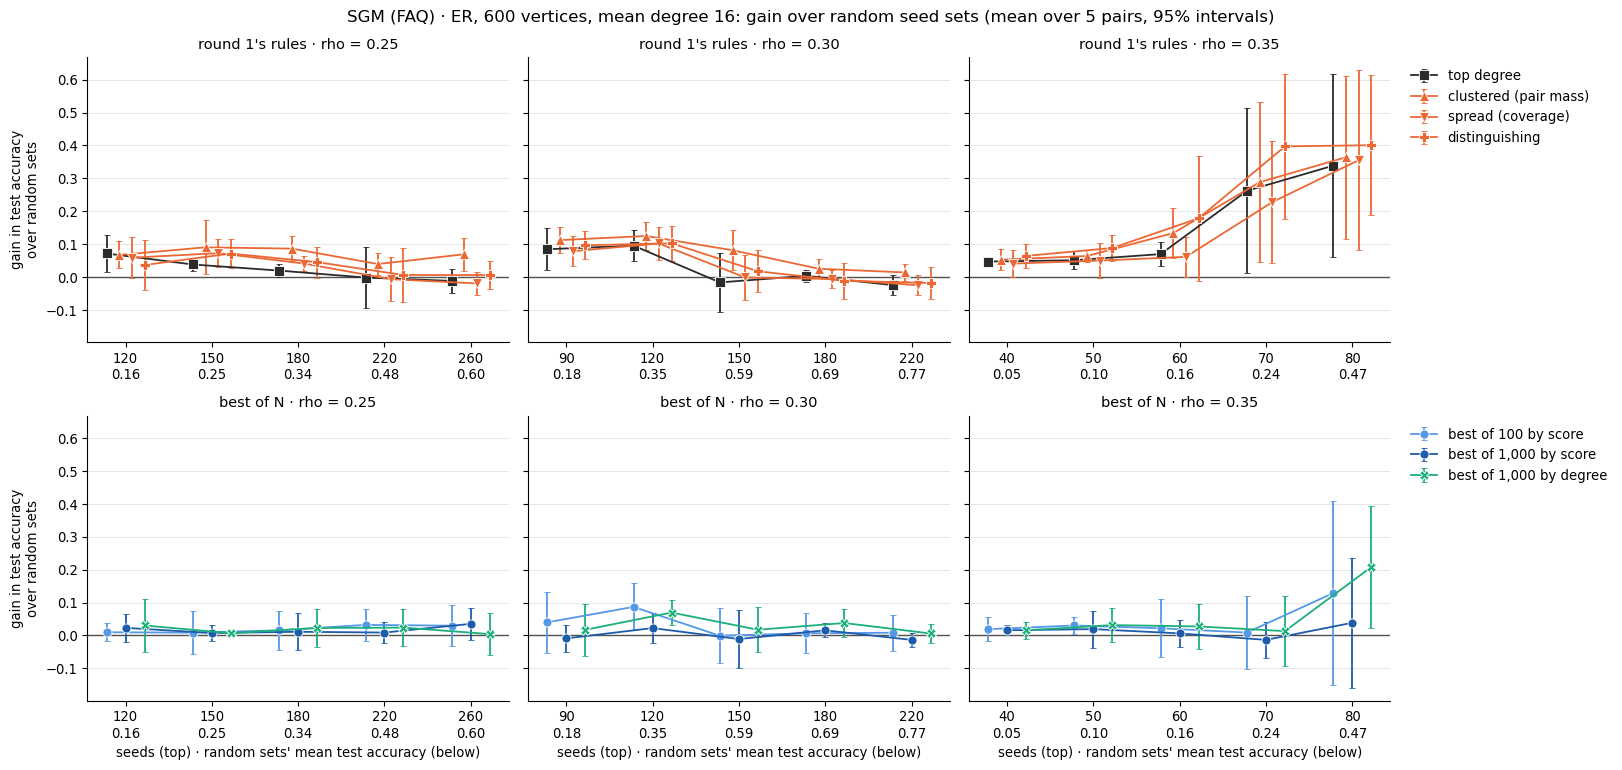

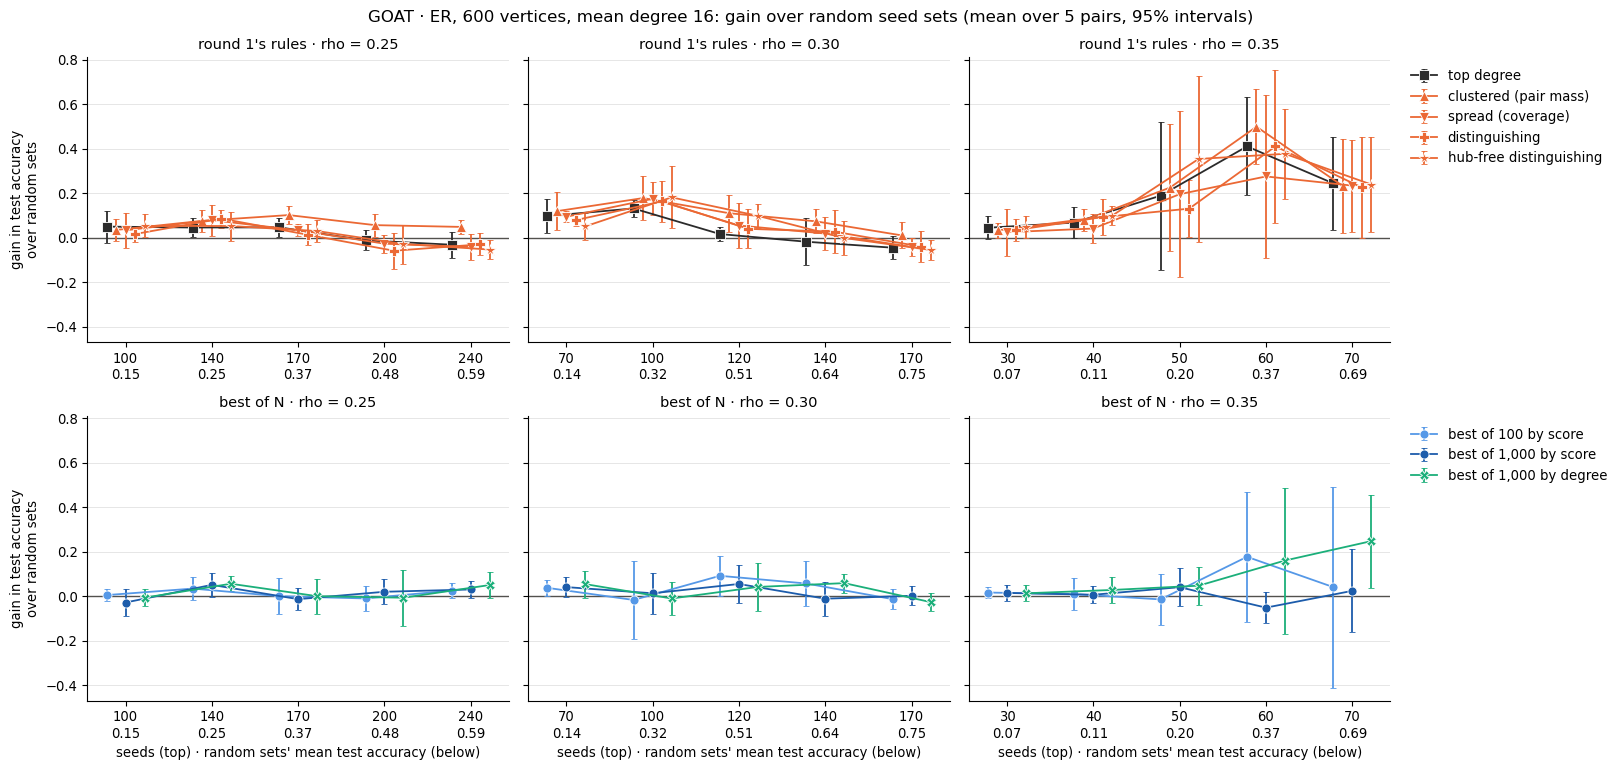

In [10]:
display(G.show_rule_table(G.rule_table(rules)))
for algorithm in G.algorithms_in(rules):
    G.plot_rules(rules, algorithm)
    plt.show()

### Where each method's sets sit among random sets

The table gives each method's core features as z-scores against the 1,000 random sets of the same pair and budget, and the frozen score's percentile among those sets. Values are averaged over ρ, pairs and budgets. Random sets sit near 0 and the 50th percentile.

The frozen weights were fitted on random sets, which rarely reach ±3 SD. Round 1's rules sit far outside that range, so the score's verdict on them is an extrapolation.

To run the same comparison with the usual non-seed accuracy, pass `outcome='accuracy'` to `rule_table` and `plot_rules`.

In [11]:
display(G.rule_feature_table(rules))

degree (z)  harmonic (z)  pair mass (z)  uniqueness (z)  frozen score  score percentile in the pool
algorithm method                                                                                                                      
SGM (FAQ) random                         0.14          0.08           0.13            0.08          0.07                         53.87
          top degree                     8.92         15.04           8.39            3.90          5.22                        100.00
          clustered (pair mass)         16.00          9.42          20.84            3.08          7.55                        100.00
          spread (coverage)              8.66         14.25           6.90            3.82          4.81                        100.00
          distinguishing                 9.35         14.08           8.46            6.27          5.65                        100.00
          best of 100 by score           2.33          1.84           2.39            1.31          1.21                         99.16
          best of 1,000 by score         3.07          2.45           2.93            1.85          1.59                        100.00
          best of 1,000 by degree        3.28          1.89           2.96            1.40          1.46                         99.70
GOAT      random                         0.03          0.04           0.05            0.01          0.02                         50.90
          top degree                     9.60         14.52           9.06            0.01          6.01                        100.00
          clustered (pair mass)         15.16          9.80          20.23            0.01          6.53                        100.00
          spread (coverage)              9.29         13.62           7.25            0.01          5.48                        100.00
          distinguishing                10.03         13.47           9.17            0.01          5.75                        100.00
          hub-free distinguishing        9.28         11.94           8.80            0.01          5.21                        100.00
          best of 100 by score           2.18          2.24           2.31            0.01          1.10                         99.07
          best of 1,000 by score         2.81          2.98           3.00            0.01          1.44                        100.00
          best of 1,000 by degree        3.29          2.08           3.07            0.01          1.22                         98.80